# TP2 – Reconstrucción 3D · Parte 1: Disparidad y nubes locales

**Objetivo de esta parte:** para cada par estéreo del objeto 1, calcular el mapa de disparidad
y convertirlo en una nube de puntos 3D local (en mm, vista desde la cámara izquierda).

**Pipeline:** calibración (ya hecha) → rectificación → disparidad (SGBM) → nube 3D (`reprojectImageTo3D`)

In [1]:
import os
import pickle #para leer el archivo .pkl de la calibración
import numpy as np
import cv2
import matplotlib.pyplot as plt
import open3d as o3d

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## 1. Calibración estéreo
La calibración se hizo con la herramienta `calib-stereo` (28 pares del tablero, cuadros de 24.2 mm).
Cargamos sus resultados: intrínsecos `K`, distorsión `dist` de cada cámara, y la pose relativa `R`, `T`
de la cámara derecha respecto de la izquierda. La **baseline** B = ‖T‖ es la distancia entre cámaras
y es la que da la escala métrica (mm) a la reconstrucción.

In [2]:
# Abrimos el archivo en modo lectura binaria ("rb") y reconstruimos el diccionario guardado
with open("data/stereo_calibration.pkl", "rb") as f:
    calib = pickle.load(f)

print(calib.keys())
print("K izquierda:\n", calib["left_K"]) #fx, fy (focal en px) y cx, cy (centro óptico)
print("T:\n", calib["T"]) #traslación entre cámaras

B = np.linalg.norm(calib["T"]) #longitud del vector T = baseline
print(f"Baseline: {B:.2f} mm")

dict_keys(['left_K', 'left_dist', 'right_K', 'right_dist', 'R', 'T', 'E', 'F', 'image_size'])
K izquierda:
 [[597.6503813    0.         942.92811171]
 [  0.         594.47622363 521.29601324]
 [  0.           0.           1.        ]]
T:
 [[-60.49610043]
 [ -0.35690132]
 [  1.06438547]]
Baseline: 60.51 mm


## 2. Rectificación estéreo
Rectificar = transformar ambas imágenes (rotación virtual de las cámaras + corrección de distorsión)
para que las **líneas epipolares queden horizontales y en la misma fila** en las dos imágenes.
Así, la correspondencia de un píxel se busca solo a lo largo de su fila, y su corrimiento
horizontal es la **disparidad** d = x_izq − x_der.

Usamos `alpha=-1` en `cv2.stereoRectify`: con `alpha=0` (lo que usa la herramienta de la cátedra)
la imagen rectificada queda con un zoom de ×4.5 y el objeto queda afuera.

In [3]:
size = calib["image_size"] #(ancho, alto) = (1920, 1080)

#Rotaciones virtuales (R1, R2), nuevas matrices de proyección (P1, P2) y matriz Q para pasar a 3D
R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(
    calib["left_K"], calib["left_dist"],
    calib["right_K"], calib["right_dist"],
    size, calib["R"], calib["T"],
    alpha=-1 #escalado automático
)

#Mapas de rectificación: para cada píxel rectificado, de qué (x, y) de la imagen original sale
#Lo calculamos solo una vez porque depende de la camara no de la foto
map_lx, map_ly = cv2.initUndistortRectifyMap(calib["left_K"], calib["left_dist"], R1, P1, size, cv2.CV_32FC1) #izq con P1 y R1
map_rx, map_ry = cv2.initUndistortRectifyMap(calib["right_K"], calib["right_dist"], R2, P2, size, cv2.CV_32FC1) #der con P2 y R2

#Máscara del borde negro: rectificamos una imagen toda blanca; donde queda negro no hay información real
blanca = np.full((size[1], size[0]), 255, np.uint8)
borde_ok = cv2.remap(blanca, map_lx, map_ly, cv2.INTER_NEAREST) > 0

print(f"focal rectificada: {P1[0, 0]:.1f} px  |  baseline: {B:.2f} mm")

focal rectificada: 595.0 px  |  baseline: 60.51 mm


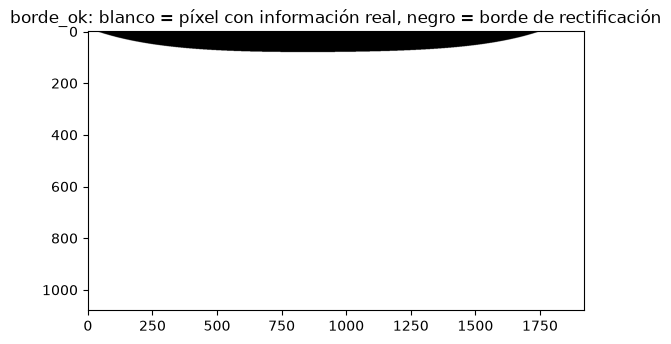

In [4]:
#lo que hicimos con la rectificacion con el blanco es sacar los bordes sin informacion que se generaron a partir de la rectificacion y mapeo.
#como no son parte de la escena SGBM no deberia actuar sobre ellos asiq ue creamos una mascara para evitarlos cuando usemos ese metodo
plt.imshow(borde_ok, cmap="gray")
plt.title("borde_ok: blanco = píxel con información real, negro = borde de rectificación")
plt.show()

In [5]:
# Comparamos la focal rectificada con alpha=0 vs alpha=-1
for a in [0, -1]:
    _, _, P1_a, _, _, _, _ = cv2.stereoRectify(
        calib["left_K"], calib["left_dist"], calib["right_K"], calib["right_dist"],
        size, calib["R"], calib["T"], alpha=a)
    print(f"alpha={a:2d}: f_rect = {P1_a[0, 0]:7.1f} px  (zoom x{P1_a[0, 0] / calib['left_K'][0, 0]:.1f})")

alpha= 0: f_rect =  2703.8 px  (zoom x4.5)
alpha=-1: f_rect =   595.0 px  (zoom x1.0)


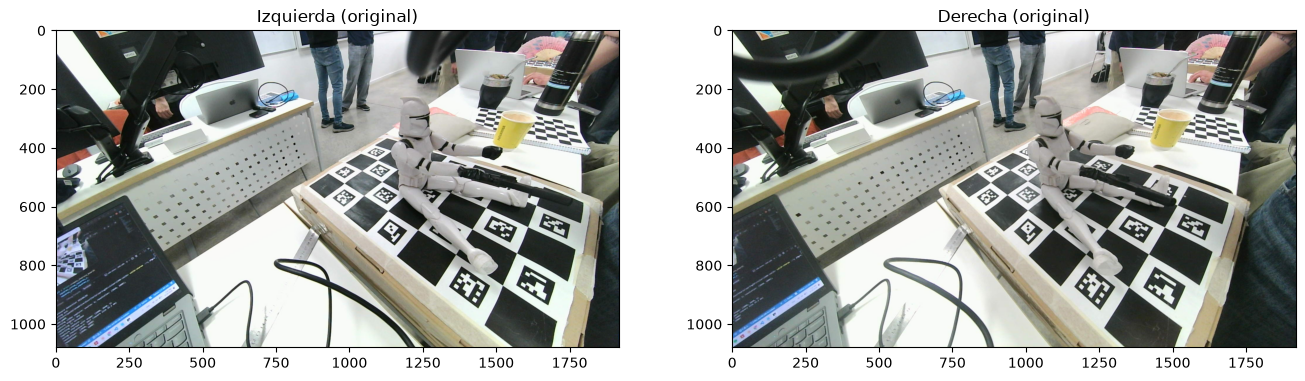

In [6]:
#Par 0 del objeto 1, sin rectificar
img_l = cv2.imread("data/objeto1/left_0.jpg")
img_r = cv2.imread("data/objeto1/right_0.jpg")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].imshow(cv2.cvtColor(img_l, cv2.COLOR_BGR2RGB))
ax[0].set_title("Izquierda (original)")
ax[1].imshow(cv2.cvtColor(img_r, cv2.COLOR_BGR2RGB))
ax[1].set_title("Derecha (original)")
plt.show()

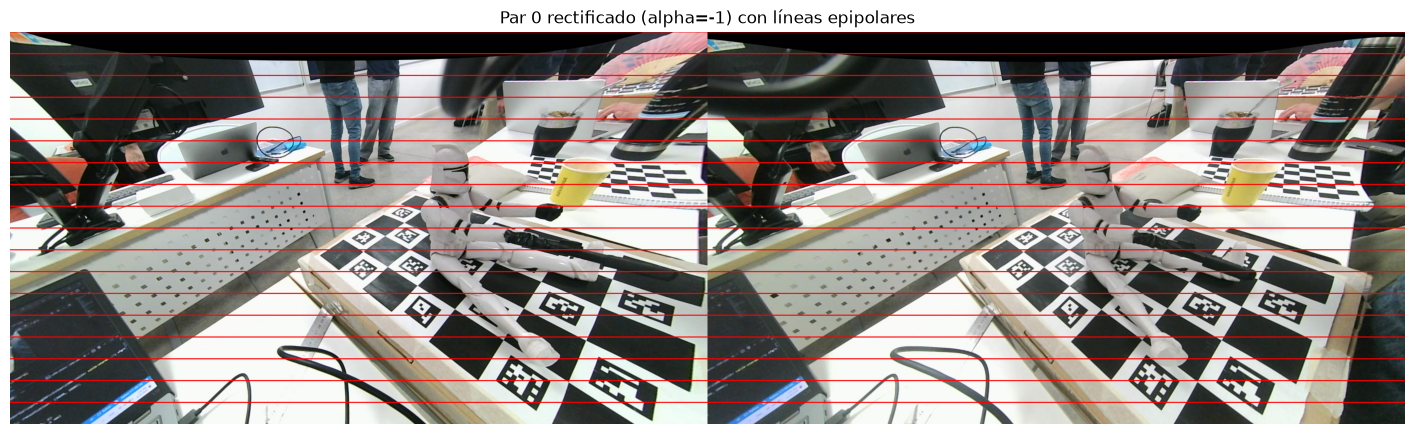

In [ ]:
# Aplicamos los mapas: cada imagen con el mapa de SU cámara
rect_l = cv2.remap(img_l, map_lx, map_ly, cv2.INTER_LINEAR)
rect_r = cv2.remap(img_r, map_rx, map_ry, cv2.INTER_LINEAR)

# Verificación visual: un mismo detalle debe quedar sobre la misma línea roja en ambas imágenes
par = np.hstack([rect_l, rect_r]) # las dos imágenes lado a lado
for y in range(0, par.shape[0], 60): # una línea cada 60 filas
    cv2.line(par, (0, y), (par.shape[1], y), (0, 0, 255), 2)

plt.figure(figsize=(18, 6))
plt.imshow(cv2.cvtColor(par, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Par 0 rectificado (alpha=-1) con líneas epipolares")
plt.savefig("figuras/rectificado_par0.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Mapa de disparidad (SGBM)
Para cada píxel de la imagen izquierda rectificada buscamos su correspondiente en la misma fila
de la derecha; la **disparidad** es el corrimiento horizontal d = x_izq − x_der (en px).
Objetos cercanos → d grande; lejanos → d chica (Z = f·B/d).

Usamos **SGBM** (*Semi-Global Block Matching*): compara bloques de píxeles a lo largo de la fila
y además penaliza saltos de disparidad entre vecinos (P1, P2), lo que da superficies más suaves
que el Block Matching simple.

- `numDisparities = 256`: rango de búsqueda. Con f ≈ 595 px y B ≈ 60.5 mm permite medir hasta
  Z_min = f·B/256 ≈ 141 mm (en algunas tomas el tablero está a ~20 cm; con 128 no alcanzaba).
  Costo: las primeras 256 columnas de la imagen

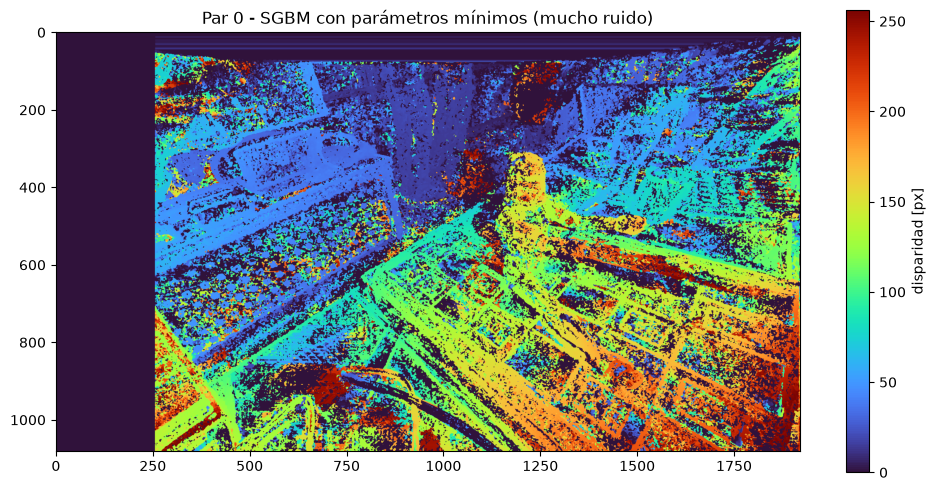

In [8]:
# SGBM solo con el rango de búsqueda y el tamaño de bloque, sin regularización ni filtros
sgbm_min = cv2.StereoSGBM_create(minDisparity=0, numDisparities=256, blockSize=5)

# compute devuelve la disparidad x16 en enteros (punto fijo); pasamos a float y dividimos
disp_min = sgbm_min.compute(rect_l, rect_r).astype(np.float32) / 16.0

plt.figure(figsize=(12, 6))
plt.imshow(disp_min, cmap="turbo", vmin=0, vmax=256)
plt.colorbar(label="disparidad [px]")
plt.title("Par 0 - SGBM con parámetros mínimos (mucho ruido)")
plt.show()

In [9]:
def crear_sgbm(bs):
    """Crea un StereoSGBM con blockSize=bs y los parámetros de regularización y filtrado."""
    return cv2.StereoSGBM_create(
        minDisparity=0,
        numDisparities=256,        # rango de búsqueda (ver markdown)
        blockSize=bs,              # tamaño del bloque que se compara (impar)
        P1=8 * 3 * bs**2,          # penalización por cambios de ±1 px de disparidad entre vecinos
        P2=32 * 3 * bs**2,         # penalización por saltos grandes (P2 > P1); el 3 = canales de color
        uniquenessRatio=10,        # descarta matches ambiguos: el mejor debe ganarle al 2º por un 10 %
        speckleWindowSize=100,     # borra "manchitas" aisladas de menos de 100 píxeles,
        speckleRange=2,            # cuya disparidad difiere en más de 2 px de su entorno
        disp12MaxDiff=1,           # chequeo izq→der vs der→izq: si difieren en más de 1 px, se descarta
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY   # variante más rápida del algoritmo
    )

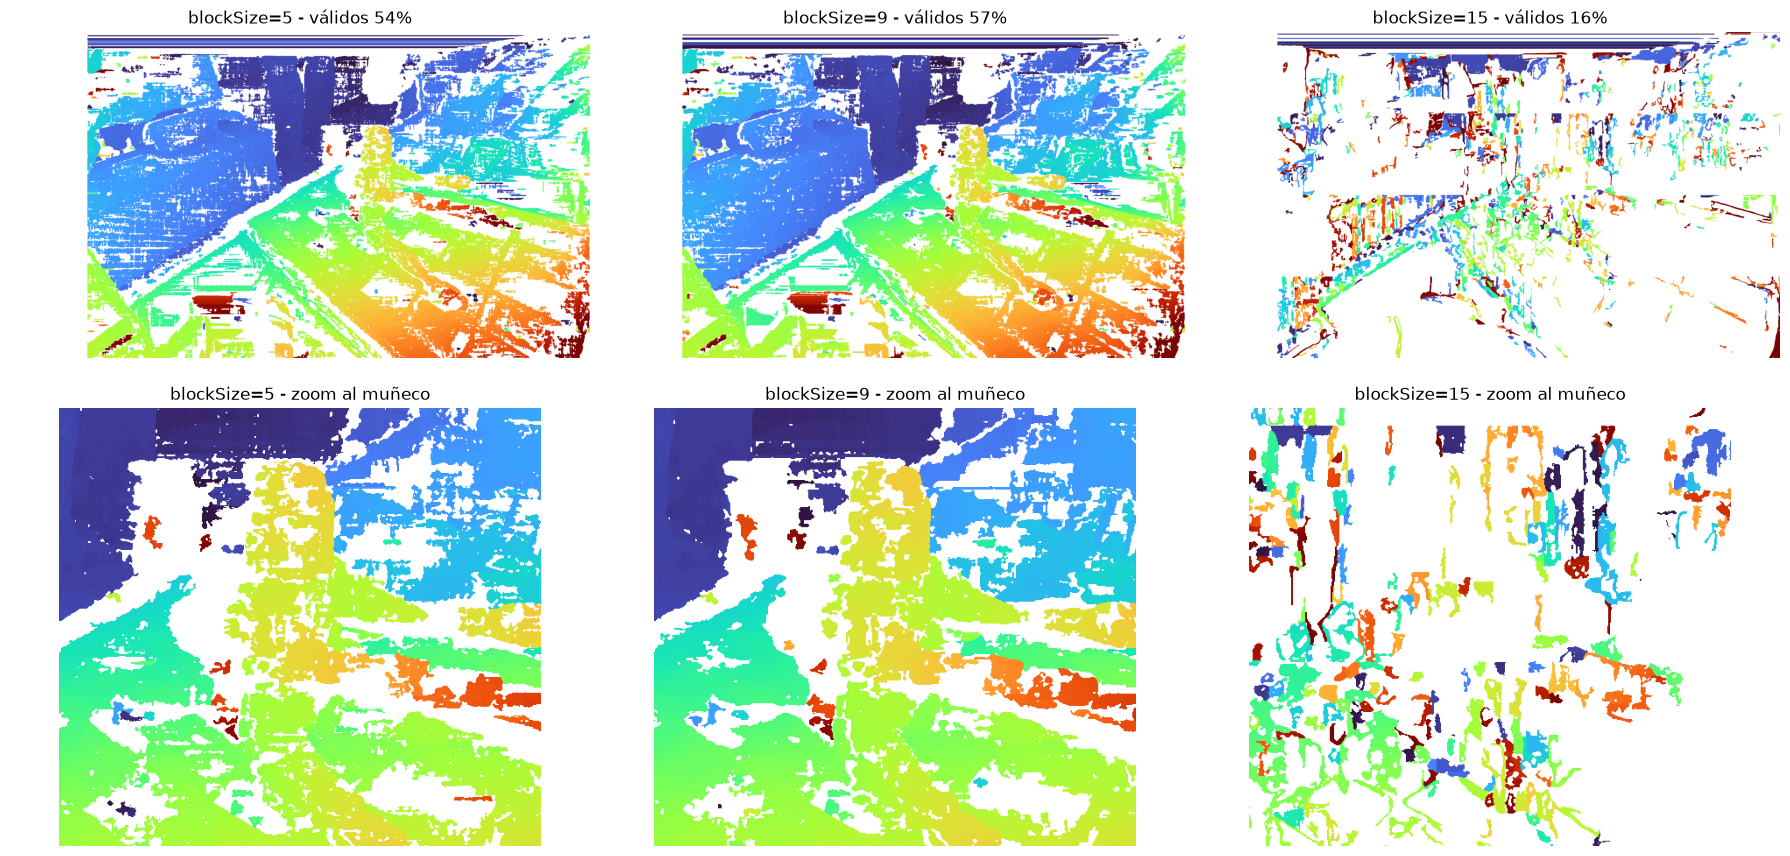

In [ ]:
#experimento para elegir el tamaño de bloque
tamanios = [5, 9, 15]
fig, ax = plt.subplots(2, len(tamanios), figsize=(18, 9))   # 2 filas: imagen completa y zoom al muñeco

for i, bs in enumerate(tamanios):
    d = crear_sgbm(bs).compute(rect_l, rect_r).astype(np.float32) / 16.0
    val = d > 0 #máscara de píxeles con disparidad válida
    d[~val] = np.nan #los inválidos no se pintan (quedan en blanco)

    ax[0, i].imshow(d, cmap="turbo", vmin=0, vmax=256)
    ax[0, i].set_title(f"blockSize={bs} - válidos {100 * val.mean():.0f}%")
    ax[1, i].imshow(d[250:750, 950:1500], cmap="turbo", vmin=0, vmax=256)   # zona del muñeco
    ax[1, i].set_title(f"blockSize={bs} - zoom al muñeco")
    for a in ax[:, i]:
        a.axis("off")

plt.tight_layout()
plt.savefig("figuras/experimento_blocksize.png", dpi=150, bbox_inches="tight")
plt.show()

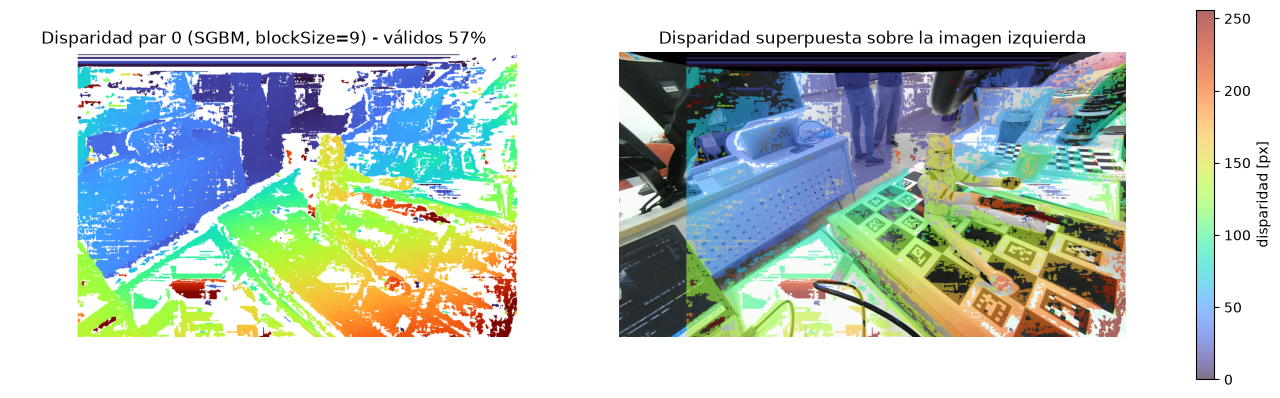

In [ ]:
# Decisión: blockSize = 9 (más relleno en el muñeco que 5; con 15 la ventana es demasiado grande)
BS = 9
sgbm = crear_sgbm(BS) #este es el matcher que usamos de acá en adelante

disp = sgbm.compute(rect_l, rect_r).astype(np.float32) / 16.0
validos = disp > 0
disp_vis = np.where(validos, disp, np.nan) # copia de disp con NaN en los inválidos, solo para graficar

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
ax[0].imshow(disp_vis, cmap="turbo", vmin=0, vmax=256)
ax[0].set_title(f"Disparidad par 0 (SGBM, blockSize={BS}) - válidos {100 * validos.mean():.0f}%")
ax[1].imshow(cv2.cvtColor(rect_l, cv2.COLOR_BGR2RGB))                   # foto de fondo
im = ax[1].imshow(disp_vis, cmap="turbo", vmin=0, vmax=256, alpha=0.6)  # disparidad encima
ax[1].set_title("Disparidad superpuesta sobre la imagen izquierda")
for a in ax:
    a.axis("off")
fig.colorbar(im, ax=ax, label="disparidad [px]", shrink=0.8)
plt.savefig("figuras/disparidad_par0.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. De la disparidad a la nube de puntos 3D
`cv2.reprojectImageTo3D(disp, Q)` aplica a cada píxel (x, y) con disparidad d:

[X Y Z W]ᵀ = Q · [x y d 1]ᵀ  →  (X/W, Y/W, Z/W),  equivalente a  Z = f·B/d,  X = (x−cx)·Z/f,  Y = (y−cy)·Z/f

Las coordenadas quedan en **mm** (porque B está en mm) y en el sistema de la **cámara izquierda rectificada**:
X → derecha, Y → abajo, Z → hacia adelante.

Filtramos los puntos no confiables: disparidad inválida, borde de rectificación y profundidades
fuera de [150, 1000] mm (Z_min del rango de búsqueda; más allá de 1 m el error crece como Z² y es fondo).

In [12]:
#Pasamos a 3d y verificamos la formula
# Para cada píxel: (X, Y, Z) en mm  ->  matriz de (alto, ancho, 3)
xyz = cv2.reprojectImageTo3D(disp, Q)
print("xyz:", xyz.shape)

# Verificación: en una zona del torso, comparamos Z calculada "a mano" (f·B/d) con la que da Q
f = P1[0, 0] #focal de la imagen RECTIFICADA (no la de K)
zona_disp = disp[400:500, 1100:1200] #recuadro de 100x100 px sobre el torso
zona_val = zona_disp > 0 #solo píxeles con disparidad válida
d_med = np.median(zona_disp[zona_val])

print(f"disparidad mediana del torso: {d_med:.1f} px")
print(f"Z a mano  (f·B/d):  {f * B / d_med:.1f} mm")
print(f"Z con Q (mediana):  {np.median(xyz[400:500, 1100:1200, 2][zona_val]):.1f} mm")

xyz: (1080, 1920, 3)
disparidad mediana del torso: 146.3 px
Z a mano  (f·B/d):  246.0 mm
Z con Q (mediana):  246.0 mm


In [13]:
#filtramos y armamos la nube
Z = xyz[:, :, 2] # profundidad de cada píxel (matriz 1080x1920)

# Nos quedamos solo con los píxeles confiables:
mascara = ((disp > 0) #disparidad válida
           & borde_ok #no es parte del borde negro de la rectificación
           & (Z > 150) & (Z < 1000)) #profundidad en rango [150, 1000] mm

puntos = xyz[mascara]                                                # (N, 3): X, Y, Z en mm
colores = cv2.cvtColor(rect_l, cv2.COLOR_BGR2RGB)[mascara] / 255.0   # (N, 3): R, G, B en [0, 1]

print(f"{len(puntos)} puntos ({100 * mascara.mean():.0f}% de los píxeles)")

889960 puntos (43% de los píxeles)


In [14]:
#visualizamos la nube entorno al muñeco
# Centro del torso = mediana de los puntos 3D válidos del recuadro de la celda 5.1
centro = np.median(xyz[400:500, 1100:1200][zona_val], axis=0)

# Distancia de cada punto al centro; nos quedamos con los que están a menos de 25 cm
cerca = np.linalg.norm(puntos - centro, axis=1) < 250
print(f"{cerca.sum()} puntos cerca del muñeco. Centro del torso: {centro.round(1)} mm")

# Armamos la nube en el formato de Open3D
nube = o3d.geometry.PointCloud()
nube.points = o3d.utility.Vector3dVector(puntos[cerca].astype(np.float64))
nube.colors = o3d.utility.Vector3dVector(colores[cerca].astype(np.float64))
ejes = o3d.geometry.TriangleMesh.create_coordinate_frame(size=100)   # ejes de la cámara: X rojo, Y verde, Z azul (100 mm)

o3d.visualization.draw_geometries([nube, ejes], lookat=centro, front=[0, 0, -1], up=[0, -1, 0], zoom=0.5)

380130 puntos cerca del muñeco. Centro del torso: [100.6 -63.7 246. ] mm


## 5. Nubes locales de todos los pares
Encapsulamos los pasos 2 a 4 en una función `nube_local(i)` y la aplicamos a los 31 pares del objeto 1.
Lo que depende solo de la cámara (mapas de rectificación, `Q`, `borde_ok`) y el matcher `sgbm`
se calculan una única vez (secciones 2 y 3); la función solo hace lo que cambia de foto a foto.

In [15]:
def nube_local(i, z_min=150, z_max=1000):
    """
    Par i del objeto 1 -> nube 3D local.
    Devuelve (puntos Nx3 en mm, colores Nx3 RGB en [0,1], disparidad en px).
    Marco de referencia: cámara izquierda RECTIFICADA (X derecha, Y abajo, Z adelante).
    Usa las variables globales map_lx/ly, map_rx/ry, sgbm, Q y borde_ok (secciones 2 y 3).
    """
    # 1. Leer y rectificar (sección 2)
    img_l = cv2.imread(f"data/objeto1/left_{i}.jpg")
    img_r = cv2.imread(f"data/objeto1/right_{i}.jpg")
    rect_l = cv2.remap(img_l, map_lx, map_ly, cv2.INTER_LINEAR)
    rect_r = cv2.remap(img_r, map_rx, map_ry, cv2.INTER_LINEAR)

    # 2. Disparidad (sección 3)
    disp = sgbm.compute(rect_l, rect_r).astype(np.float32) / 16.0

    # 3. A 3D y filtrado (sección 4)
    xyz = cv2.reprojectImageTo3D(disp, Q)
    Z = xyz[:, :, 2]
    mascara = (disp > 0) & borde_ok & (Z > z_min) & (Z < z_max)

    puntos = xyz[mascara]
    colores = cv2.cvtColor(rect_l, cv2.COLOR_BGR2RGB)[mascara] / 255.0
    return puntos, colores, disp

In [16]:
def guardar_ply(ruta, puntos, colores, voxel=None):
    """Guarda la nube en .ply binario. Si se pasa `voxel` (mm), la submuestrea antes de guardar."""
    nube = o3d.geometry.PointCloud()
    nube.points = o3d.utility.Vector3dVector(puntos.astype(np.float64))
    nube.colors = o3d.utility.Vector3dVector(colores.astype(np.float64))
    if voxel is not None: # solo submuestrea si se lo pedís
        nube = nube.voxel_down_sample(voxel_size=voxel)
    o3d.io.write_point_cloud(ruta, nube)
    return len(nube.points)

os.makedirs("salidas/nubes_locales", exist_ok=True) # crea la carpeta (si ya existe, no pasa nada)

n_pares = len([a for a in os.listdir("data/objeto1") if a.startswith("left_")])
print(f"{n_pares} pares encontrados\n")

for i in range(n_pares):
    p, c, d = nube_local(i)
    n = guardar_ply(f"salidas/nubes_locales/nube_{i}.ply", p, c)
    print(f"par {i:2d}: válidos {100 * (d > 0).mean():3.0f}%  ->  {n:6d} puntos guardados")

31 pares encontrados

par  0: válidos  57%  ->  889960 puntos guardados
par  1: válidos  54%  ->  877535 puntos guardados
par  2: válidos  54%  ->  812394 puntos guardados
par  3: válidos  53%  ->  975623 puntos guardados
par  4: válidos  50%  ->  643880 puntos guardados
par  5: válidos  55%  ->  885631 puntos guardados
par  6: válidos  50%  ->  669857 puntos guardados
par  7: válidos  44%  ->  669916 puntos guardados
par  8: válidos  48%  ->  703569 puntos guardados
par  9: válidos  42%  ->  557825 puntos guardados
par 10: válidos  51%  ->  869222 puntos guardados
par 11: válidos  44%  ->  578920 puntos guardados
par 12: válidos  51%  ->  951451 puntos guardados
par 13: válidos  51%  ->  933643 puntos guardados
par 14: válidos  57%  ->  986810 puntos guardados
par 15: válidos  45%  ->  580973 puntos guardados
par 16: válidos  49%  ->  644913 puntos guardados
par 17: válidos  52%  ->  800339 puntos guardados
par 18: válidos  54%  ->  926794 puntos guardados
par 19: válidos  46%  ->  35

## Notas para las etapas siguientes (poses y fusión)
- Las nubes locales están en **mm** y en el marco de la **cámara izquierda rectificada**
  (X derecha, Y abajo, Z adelante). Ese marco está rotado `R1` respecto de la cámara izquierda original.
- Para que las poses coincidan con las nubes: hacer `solvePnP` sobre la imagen **rectificada** (`rect_l`)
  con `K = P1[:, :3]` y distorsión cero; o bien hacerlo en la imagen original y pasar la nube con X_orig = R1ᵀ·X_rect.
- La rectificación usa `alpha=-1`; **no usar** `data/stereo_maps.pkl` (tiene `alpha=0`, zoom ×4.5).
- Las nubes `.ply` no se suben a git (carpeta `salidas/`): se regeneran corriendo este notebook.
- Pares 19–30 (tomas bajas, rasantes al tablero) tienen menos puntos válidos.